# CreditParity – Step 6
**BUS/FIN 241A · Final Team Project · Profitable, Fair Lending Decisions**

**Step 6:** Fairness – group metrics, proxies and bias mitigation

## Step 6 · Fairness

**Question.** Does CreditParity treat applicants differently by **sex**, **age** or **foreign worker status**, and can we fix it?

**Three model variants.** All are logistic regressions with the same preprocessing; only the input or the training weights differ.
- **(a) All features** – the model from Steps 4 and 5.
- **(b) Without sensitive features** – `Sex`, `Age` and `ForeignWorker` are removed ("fairness through unawareness").
- **(c) Bias mitigation by reweighing** – all features, but the training applications are reweighted so that, in the weighted training data, default is statistically independent of the combination of age group, sex and foreign worker status (Kamiran & Calders, 2012). The model stays an ordinary logistic regression, so it still gives probabilities and can be explained with SHAP.

**Decision rule.** Each variant declines an application if its default probability is at or above *its own* cost-optimal threshold (5:1 cost matrix, chosen on out-of-fold predictions as in Step 5). The zones use this threshold as the lower boundary and the fixed upper boundary of 0.37.

**Metrics per group.**
- **Rejection rate** – share of applications declined (yellow + red zone, i.e. PD ≥ threshold).
- **Recall** – share of the group's defaults that are caught.
- **False positive rate (FPR)** – share of the group's *good* customers that are declined.
- **Demographic Parity Difference (DPD)** – largest gap in rejection rates between groups. 0 = all groups are declined equally often.
- **Equal Opportunity Difference (EOD)** – largest gap between groups in the FPR, i.e. in the chance that a *creditworthy* applicant is declined. In lending, equal opportunity means that good customers get the same chance of approval regardless of their group. (We also report the recall gap.)

**Data.** Variants are compared on the **out-of-fold predictions of the 4,000 training applications** (larger groups, no test-set use for decisions). The **test set** is used once at the end to confirm the results. Age groups follow Step 2: 19–25, 26–35, 36–50, 51+.

In [1]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from fairlearn.metrics import (MetricFrame, selection_rate, false_positive_rate,
                               true_positive_rate, count)
from fairlearn.preprocessing import CorrelationRemover   # pip install fairlearn (also in Colab)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)
ZONE_COLORS = {"Green": "#55A868", "Yellow": "#DDAA33", "Red": "#C44E52"}
VARIANT_COLORS = ["#4C72B0", "#8C8C8C", "#55A868"]

COST_FN, COST_FP = 5, 1
T_UPPER = 0.37                     # fixed upper zone boundary (Step 5)
SENSITIVE = ["Sex", "Age", "ForeignWorker"]
AGE_BINS, AGE_LABELS = [18, 25, 35, 50, 100], ["19-25", "26-35", "36-50", "51+"]

In [2]:
# Load data
# In the repo the file lives in data/. In Google Colab, upload the CSV via the
# folder icon on the left and set DATA_PATH = "german_credit_data_biased_training.csv"
DATA_PATH = "../data/german_credit_data_biased_training.csv"
df = pd.read_csv(DATA_PATH)
df["y"] = (df["Risk"] == "Risk").astype(int)

X = df.drop(columns=["Risk", "y"])
y = df["y"]
categorical = X.select_dtypes(include=["object", "string"]).columns.tolist()
numeric = X.select_dtypes(include="number").columns.tolist()

# Same stratified 80/20 split as in Steps 3 to 5
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

def age_group(data):
    return pd.cut(data["Age"], AGE_BINS, labels=AGE_LABELS).astype(str)

def groups_of(data):
    """The three sensitive attributes used for the fairness analysis."""
    return {"Sex": data["Sex"], "Age group": age_group(data), "ForeignWorker": data["ForeignWorker"]}

for name, g in groups_of(X_train).items():
    print(name, g.value_counts().sort_index().to_dict())

Sex {'female': 1518, 'male': 2482}
Age group {'19-25': 771, '26-35': 1191, '36-50': 1656, '51+': 382}
ForeignWorker {'no': 100, 'yes': 3900}


### Model variants

Reweighing gives each combination of (group, outcome) the weight *expected share / observed share*. Groups in which defaults are over-represented get lower weights for their defaults and higher weights for their good customers, so the model can no longer learn the group's higher default rate from the data. The weights are computed on the training part of each fold only.

In [3]:
def make_model(features):
    cat = [c for c in categorical if c in features]
    num = [c for c in numeric if c in features]
    return Pipeline([
        ("prep", ColumnTransformer([
            ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
            ("num", StandardScaler(), num)])),
        ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ])

def reweighing_weights(data, y_true, keys=("Age group", "Sex", "ForeignWorker")):
    """Kamiran & Calders reweighing: weight = P(group) * P(y) / P(group, y)."""
    g = groups_of(data)
    group = pd.Series(["|".join(t) for t in zip(*[g[k].astype(str) for k in keys])],
                      index=data.index)
    w = pd.Series(1.0, index=data.index)
    for gv in group.unique():
        for label in [0, 1]:
            m = (group == gv) & (y_true == label)
            if m.any():
                w[m] = (group == gv).mean() * (y_true == label).mean() / m.mean()
    return w.to_numpy()

ALL_FEATURES = X.columns.tolist()
NON_SENSITIVE = [c for c in ALL_FEATURES if c not in SENSITIVE]

VARIANTS = {
    "(a) All features":              {"features": ALL_FEATURES,  "reweigh": False},
    "(b) Without sensitive features": {"features": NON_SENSITIVE, "reweigh": False},
    "(c) Reweighing":                {"features": ALL_FEATURES,  "reweigh": True},
}

def fit_variant(spec, data, y_true, keys=("Age group", "Sex", "ForeignWorker")):
    model = make_model(spec["features"])
    if spec["reweigh"]:
        model.fit(data, y_true, model__sample_weight=reweighing_weights(data, y_true, keys))
    else:
        model.fit(data, y_true)
    return model

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def oof_predictions(spec, **kw):
    """Out-of-fold default probabilities on the training set."""
    p = np.zeros(len(y_train))
    for tr, va in cv.split(X_train, y_train):
        m = fit_variant(spec, X_train.iloc[tr], y_train.iloc[tr], **kw)
        p[va] = m.predict_proba(X_train.iloc[va])[:, 1]
    return p

THRESHOLDS = np.round(np.arange(0.01, 1.00, 0.01), 2)

def cost(p, y_true, t):
    return COST_FN * ((p < t) & (y_true == 1)).sum() + COST_FP * ((p >= t) & (y_true == 0)).sum()

def cost_optimal_threshold(p, y_true):
    return float(THRESHOLDS[int(np.argmin([cost(p, y_true, t) for t in THRESHOLDS]))])

y_tr = y_train.to_numpy()
oof, thresholds = {}, {}
for name, spec in VARIANTS.items():
    oof[name] = oof_predictions(spec)
    thresholds[name] = cost_optimal_threshold(oof[name], y_tr)
    print(f"{name:32s} cost-optimal threshold {thresholds[name]:.2f} | "
          f"out-of-fold ROC AUC {roc_auc_score(y_tr, oof[name]):.3f}")

(a) All features                 cost-optimal threshold 0.11 | out-of-fold ROC AUC 0.856
(b) Without sensitive features   cost-optimal threshold 0.13 | out-of-fold ROC AUC 0.852


(c) Reweighing                   cost-optimal threshold 0.16 | out-of-fold ROC AUC 0.807


### a) Group metrics for each variant (out-of-fold, training set)

In [4]:
def group_report(p, y_true, t, data):
    """Per-group metrics and DPD/EOD for one variant."""
    decline = (p >= t).astype(int)
    by_group, summary = {}, {}
    for attr, g in groups_of(data).items():
        mf = MetricFrame(
            metrics={"Applications": count, "Default rate": lambda yt, yp: yt.mean(),
                     "Rejection rate": selection_rate, "Recall": true_positive_rate,
                     "FPR": false_positive_rate},
            y_true=y_true, y_pred=decline, sensitive_features=g.to_numpy())
        by_group[attr] = mf.by_group
        diff = mf.difference()
        summary[attr] = {"DPD": diff["Rejection rate"], "EOD (FPR gap)": diff["FPR"],
                         "Recall gap": diff["Recall"]}
    return by_group, pd.DataFrame(summary).T

reports = {name: group_report(oof[name], y_tr, thresholds[name], X_train) for name in VARIANTS}

for attr in ["Sex", "Age group", "ForeignWorker"]:
    table = pd.concat({name: reports[name][0][attr][["Applications", "Default rate", "Rejection rate",
                                                     "Recall", "FPR"]]
                       for name in VARIANTS}, names=["Variant", attr])
    print(f"\n=== {attr} ===")
    display(table.round(3))


=== Sex ===


Applications  Default rate  \
Variant                        Sex                                  
(a) All features               female        1518.0         0.298   
                               male          2482.0         0.356   
(b) Without sensitive features female        1518.0         0.298   
                               male          2482.0         0.356   
(c) Reweighing                 female        1518.0         0.298   
                               male          2482.0         0.356   

                                       Rejection rate  Recall    FPR  
Variant                        Sex                                    
(a) All features               female           0.603   0.960  0.452  
                               male             0.724   0.948  0.601  
(b) Without sensitive features female           0.491   0.914  0.311  
                               male             0.741   0.957  0.622  
(c) Reweighing                 female           0.638   0.918  0.518  
                               male             0.681   0.901  0.560


=== Age group ===


Applications  Default rate  \
Variant                        Age group                               
(a) All features               19-25             771.0         0.074   
                               26-35            1191.0         0.207   
                               36-50            1656.0         0.443   
                               51+               382.0         0.783   
(b) Without sensitive features 19-25             771.0         0.074   
                               26-35            1191.0         0.207   
                               36-50            1656.0         0.443   
                               51+               382.0         0.783   
(c) Reweighing                 19-25             771.0         0.074   
                               26-35            1191.0         0.207   
                               36-50            1656.0         0.443   
                               51+               382.0         0.783   

                                          Rejection rate  Recall    FPR  
Variant                        Age group                                 
(a) All features               19-25               0.204   0.667  0.167  
                               26-35               0.592   0.894  0.513  
                               36-50               0.890   0.975  0.822  
                               51+                 0.990   0.997  0.964  
(b) Without sensitive features 19-25               0.169   0.649  0.130  
                               26-35               0.537   0.866  0.452  
                               36-50               0.869   0.970  0.789  
                               51+                 0.984   0.993  0.952  
(c) Reweighing                 19-25               0.447   0.947  0.408  
                               26-35               0.624   0.894  0.553  
                               36-50               0.746   0.896  0.627  
                               51+                 0.877   0.936  0.663


=== ForeignWorker ===


Applications  Default rate  \
Variant                        ForeignWorker                               
(a) All features               no                    100.0         0.540   
                               yes                  3900.0         0.329   
(b) Without sensitive features no                    100.0         0.540   
                               yes                  3900.0         0.329   
(c) Reweighing                 no                    100.0         0.540   
                               yes                  3900.0         0.329   

                                              Rejection rate  Recall    FPR  
Variant                        ForeignWorker                                 
(a) All features               no                      0.980   1.000  0.957  
                               yes                     0.671   0.950  0.534  
(b) Without sensitive features no                      0.920   0.963  0.870  
                               yes                     0.639   0.941  0.491  
(c) Reweighing                 no                      0.820   0.870  0.761  
                               yes                     0.661   0.909  0.539

In [5]:
# Summary: fairness gaps, cost and ROC AUC per variant
rows = []
for name in VARIANTS:
    s = reports[name][1]
    rows.append({"Variant": name, "Threshold": thresholds[name],
                 "Cost": cost(oof[name], y_tr, thresholds[name]),
                 "ROC AUC": roc_auc_score(y_tr, oof[name]),
                 "Recall": ((oof[name] >= thresholds[name]) & (y_tr == 1)).sum() / y_tr.sum(),
                 **{f"DPD {a}": s.loc[a, "DPD"] for a in s.index},
                 **{f"EOD {a}": s.loc[a, "EOD (FPR gap)"] for a in s.index}})
summary_oof = pd.DataFrame(rows).set_index("Variant")
summary_oof.round(3).T

Variant,(a) All features,(b) Without sensitive features,(c) Reweighing
Threshold,0.110,0.130,0.160
Cost,1762.000,1711.000,2067.000
ROC AUC,0.856,0.852,0.807
Recall,0.952,0.942,0.907
DPD Sex,0.121,0.251,0.044
DPD Age group,0.786,0.816,0.429
DPD ForeignWorker,0.309,0.281,0.159
EOD Sex,0.149,0.311,0.041
EOD Age group,0.797,0.822,0.255
EOD ForeignWorker,0.423,0.378,0.222


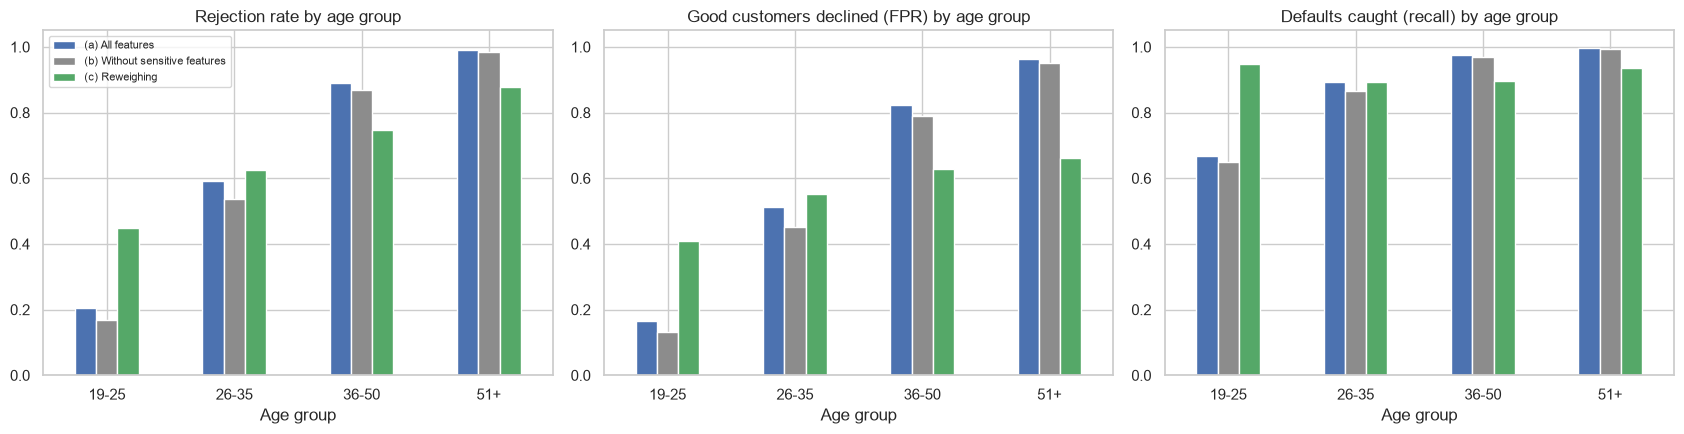

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (metric, title) in zip(axes, [("Rejection rate", "Rejection rate"),
                                      ("FPR", "Good customers declined (FPR)"),
                                      ("Recall", "Defaults caught (recall)")]):
    data = pd.DataFrame({name: reports[name][0]["Age group"][metric] for name in VARIANTS})
    data.plot.bar(ax=ax, color=VARIANT_COLORS, rot=0, legend=(metric == "Rejection rate"))
    ax.set_title(f"{title} by age group")
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("Age group")
axes[0].legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

**Result (a) – group metrics (out-of-fold, 4,000 training applications).**

| | (a) All features | (b) Without sensitive features | (c) Reweighing |
|---|---|---|---|
| Threshold | 0.11 | 0.13 | 0.16 |
| Cost | 1,762 | 1,711 | 2,067 (+17%) |
| ROC AUC | 0.856 | 0.852 | 0.807 |
| Recall | 0.952 | 0.942 | 0.907 |
| DPD / EOD – Age group | 0.79 / 0.80 | 0.82 / 0.82 | **0.43 / 0.26** |
| DPD / EOD – Sex | 0.12 / 0.15 | 0.25 / 0.31 | **0.04 / 0.04** |
| DPD / EOD – ForeignWorker | 0.31 / 0.42 | 0.28 / 0.38 | **0.16 / 0.22** |

- **Age is by far the largest gap.** With all features, 20% of applicants aged 19–25 are declined, but 99% of those aged 51+. More importantly for fairness, **96% of the *good* customers aged 51+ are declined, compared with 17% of good customers aged 19–25** (EOD 0.80). Part of the rejection gap reflects real differences in the data (default rate 7% vs. 78%), which is why demographic parity alone is not the right target for age. The FPR gap, however, shows that creditworthy older applicants have almost no chance of approval.
- **Sex.** Men are declined more often than women (72% vs. 60%), in line with their higher default rate (36% vs. 30%). Good male customers are also declined more often (FPR 0.60 vs. 0.45).
- **ForeignWorker.** The small group of applicants who are *not* foreign workers (100 in the training set, default rate 54%) is declined in 98% of cases.
- **(b) Dropping the sensitive features does not reduce the gaps.** The age gap stays the same (EOD 0.82), and the sex gap even doubles (EOD 0.31): without `Sex`, the model can no longer offset what the other features say about men and women. Cost and ROC AUC are almost unchanged.
- **(c) Reweighing reduces every gap**: the age EOD falls by two thirds (0.80 → 0.26), the sex gap almost disappears and the ForeignWorker gap halves. The price is a weaker model (ROC AUC 0.856 → 0.807), 17% higher cost and slightly lower recall (0.95 → 0.91).
- **Leveling down.** Reweighing narrows the age gap from both sides: good customers aged 51+ are declined less often (0.96 → 0.66), but good customers aged 19–25 are declined *more* often (0.17 → 0.41). A fairer model is not automatically better for every group.

### b) Why dropping sensitive features is not enough: proxies

If the remaining 17 features can predict a sensitive attribute, the model can still treat the groups differently without ever seeing the attribute. We test this by predicting each sensitive attribute from the non-sensitive features only (5-fold CV, logistic regression). A ROC AUC of 0.5 means "no information", 1.0 means "perfect proxy".

In [7]:
proxy_targets = {
    "Age 51+": (X_train["Age"] > 50).astype(int),
    "Age 36+": (X_train["Age"] > 35).astype(int),
    "Female": (X_train["Sex"] == "female").astype(int),
    "Not a foreign worker": (X_train["ForeignWorker"] == "no").astype(int),
}
proxy_rows = []
for target, t_y in proxy_targets.items():
    auc = cross_val_score(make_model(NON_SENSITIVE), X_train[NON_SENSITIVE], t_y,
                          cv=cv, scoring="roc_auc")
    proxy_rows.append({"Sensitive attribute": target, "ROC AUC from other features": auc.mean(),
                       "Std": auc.std()})
pd.DataFrame(proxy_rows).set_index("Sensitive attribute").round(3)

,ROC AUC from other features,Std
Sensitive attribute,,
Age 51+,0.904,0.012
Age 36+,0.883,0.008
Female,0.692,0.017
Not a foreign worker,0.646,0.015


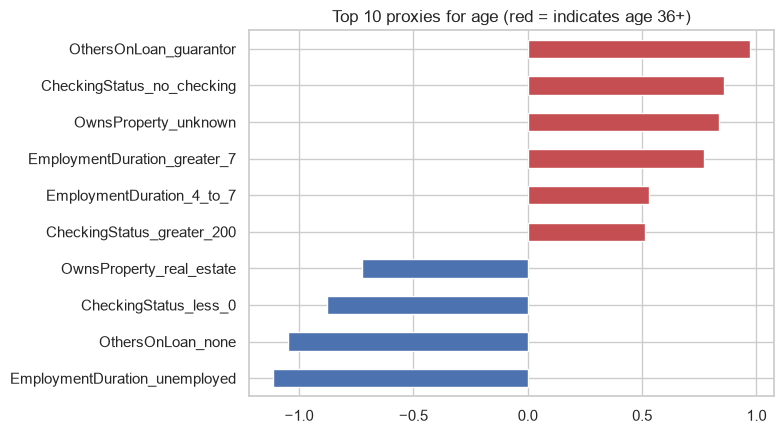

In [8]:
# Which features carry the age information? Strongest predictors of "Age 36+"
proxy_model = make_model(NON_SENSITIVE).fit(X_train[NON_SENSITIVE], proxy_targets["Age 36+"])
names = [n.split("__", 1)[1] for n in proxy_model.named_steps["prep"].get_feature_names_out()]
coef = pd.Series(proxy_model.named_steps["model"].coef_[0], index=names)
top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(10)
top.sort_values().plot.barh(figsize=(8, 4.5),
    color=["#C44E52" if v > 0 else "#4C72B0" for v in top.sort_values()])
plt.title("Top 10 proxies for age (red = indicates age 36+)")
plt.tight_layout()
plt.show()

In [9]:
# Does mitigation work without the sensitive attributes? And how does another method compare?
extra = {
    "(c) Reweighing (all features)": oof["(c) Reweighing"],
    "Reweighing without sensitive features": oof_predictions(
        {"features": NON_SENSITIVE, "reweigh": True}),
}

def correlation_remover_oof(alpha):
    """fairlearn CorrelationRemover: removes the linear correlation of all features with
    Age, Sex and ForeignWorker (alpha = 1: fully, alpha = 0.5: halfway)."""
    p = np.zeros(len(y_train))
    for tr, va in cv.split(X_train, y_train):
        prep = ColumnTransformer([
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
            ("num", StandardScaler(), numeric)])
        prep.fit(X_train.iloc[tr])
        ids = [i for i, n in enumerate(prep.get_feature_names_out())
               if n == "num__Age" or n.startswith(("cat__Sex_", "cat__ForeignWorker_"))]
        m = Pipeline([("prep", prep),
                      ("cr", CorrelationRemover(sensitive_feature_ids=ids, alpha=alpha)),
                      ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])
        m.fit(X_train.iloc[tr], y_train.iloc[tr])
        p[va] = m.predict_proba(X_train.iloc[va])[:, 1]
    return p

for alpha in [0.5, 1.0]:
    extra[f"CorrelationRemover (alpha = {alpha})"] = correlation_remover_oof(alpha)

rows = []
for name, p in {"(a) All features": oof["(a) All features"], **extra}.items():
    t = cost_optimal_threshold(p, y_tr)
    by_group, s = group_report(p, y_tr, t, X_train)
    fpr_age = by_group["Age group"]["FPR"]
    rows.append({"Method": name, "Threshold": t, "Cost": cost(p, y_tr, t),
                 "ROC AUC": roc_auc_score(y_tr, p),
                 "FPR 19-25": fpr_age["19-25"], "FPR 51+": fpr_age["51+"],
                 "EOD Age group": s.loc["Age group", "EOD (FPR gap)"],
                 "EOD Sex": s.loc["Sex", "EOD (FPR gap)"]})
pd.DataFrame(rows).set_index("Method").round(3)

,Threshold,Cost,ROC AUC,FPR 19-25,FPR 51+,EOD Age group,EOD Sex
Method,,,,,,,
(a) All features,0.11,1762,0.856,0.167,0.964,0.797,0.149
(c) Reweighing (all features),0.16,2067,0.807,0.408,0.663,0.255,0.041
Reweighing without sensitive features,0.17,1911,0.831,0.254,0.964,0.710,0.225
CorrelationRemover (alpha = 0.5),0.13,1838,0.836,0.328,0.831,0.504,0.191
CorrelationRemover (alpha = 1.0),0.11,2565,0.730,0.978,0.711,0.267,0.032


**Result (b) – proxies.**
- **Age can be reconstructed from the other features.** Without seeing `Age`, a logistic regression identifies applicants aged 51+ with a ROC AUC of **0.90** (36+: 0.88). The strongest proxies are a guarantor on the loan (`OthersOnLoan`), the checking account status, unknown property and employment duration over 7 years. Sex (0.69) and foreign worker status (0.65) are weaker, but still not hidden.
- **Mitigation needs the sensitive attribute.** Reweighing *without* the sensitive features hardly helps (age EOD 0.71; 96% of good customers aged 51+ are still declined). The model can only offset the proxies if it knows the attribute it should be fair about. This is the opposite of "fairness through unawareness".
- **Another method for comparison.** fairlearn's `CorrelationRemover` removes the correlation between the features and the sensitive attributes. Halfway (alpha = 0.5) it reduces the age EOD to 0.50 at a cost of 1,838. Fully applied (alpha = 1) it overcorrects: ROC AUC falls to 0.73 and 98% of good customers aged 19–25 are declined. We also tried fairlearn's `ExponentiatedGradient`, but it optimizes accuracy rather than our 5:1 cost matrix and produced unusable probabilities on this data, so it is not shown.

**Answer to the key question.** Simply dropping sensitive features is **not enough**. The age information is still in the data through proxies, and the age gap stays at the same level.

### c) Fairness per zone

Which groups are approved automatically, sent to an analyst, or declined with an explanation? We show the zone shares per group for each variant (lower boundary = the variant's own threshold, upper boundary = 0.37).

In [10]:
def zone_of(p, lower, upper=T_UPPER):
    return np.where(p < lower, "Green", np.where(p >= upper, "Red", "Yellow"))

zone_rows = []
for name in VARIANTS:
    zone = pd.Series(zone_of(oof[name], thresholds[name]), index=X_train.index)
    for attr, g in groups_of(X_train).items():
        shares = pd.crosstab(g, zone, normalize="index").reindex(columns=["Green", "Yellow", "Red"],
                                                                 fill_value=0)
        for grp, r in shares.iterrows():
            zone_rows.append({"Variant": name, "Attribute": attr, "Group": grp, **r.to_dict()})
zone_shares = pd.DataFrame(zone_rows).set_index(["Variant", "Attribute", "Group"])
zone_shares.round(3)

Green  Yellow    Red
Variant                        Attribute     Group                       
(a) All features               Sex           female  0.397   0.268  0.335
                                             male    0.276   0.320  0.405
                               Age group     19-25   0.796   0.180  0.023
                                             26-35   0.408   0.432  0.160
                                             36-50   0.110   0.318  0.572
                                             51+     0.010   0.052  0.937
                               ForeignWorker no      0.020   0.310  0.670
                                             yes     0.329   0.300  0.371
(b) Without sensitive features Sex           female  0.509   0.228  0.263
                                             male    0.259   0.288  0.454
                               Age group     19-25   0.831   0.140  0.029
                                             26-35   0.463   0.369  0.169
                                             36-50   0.131   0.295  0.574
                                             51+     0.016   0.065  0.919
                               ForeignWorker no      0.080   0.340  0.580
                                             yes     0.361   0.263  0.376
(c) Reweighing                 Sex           female  0.362   0.285  0.353
                                             male    0.319   0.279  0.402
                               Age group     19-25   0.553   0.241  0.206
                                             26-35   0.376   0.317  0.306
                                             36-50   0.254   0.287  0.459
                                             51+     0.123   0.220  0.657
                               ForeignWorker no      0.180   0.360  0.460
                                             yes     0.339   0.279  0.382

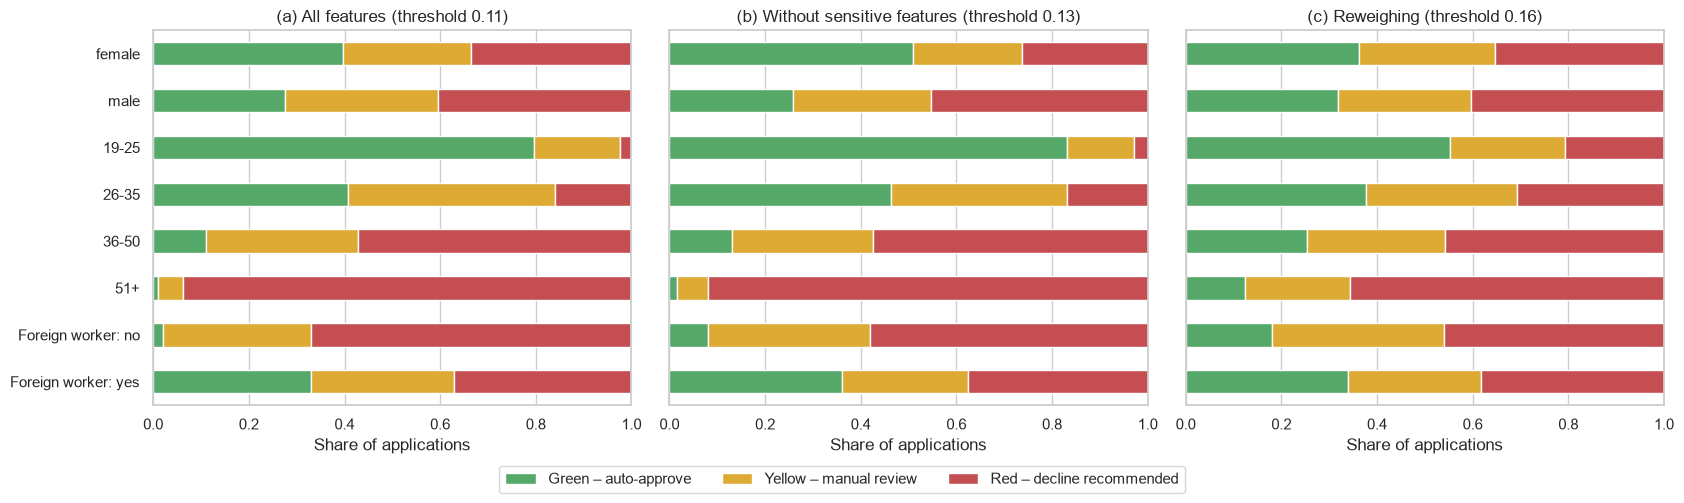

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)
for ax, name in zip(axes, VARIANTS):
    zs = zone_shares.loc[name]
    zs.index = [f"Foreign worker: {g}" if a == "ForeignWorker" else g for a, g in zs.index]
    zs.plot.barh(stacked=True, ax=ax, color=[ZONE_COLORS[z] for z in zs.columns], legend=False)
    ax.set_title(f"{name} (threshold {thresholds[name]:.2f})")
    ax.set_xlim(0, 1)
    ax.set_xlabel("Share of applications")
    ax.invert_yaxis()
fig.legend(["Green – auto-approve", "Yellow – manual review", "Red – decline recommended"],
           loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.06))
plt.tight_layout()
plt.show()

**Result (c) – fairness per zone (out-of-fold).**

| Zone shares, model (a) | 🟢 Green | 🟡 Yellow | 🔴 Red |
|---|---|---|---|
| Age 19–25 | 79.6% | 18.0% | 2.3% |
| Age 26–35 | 40.8% | 43.2% | 16.0% |
| Age 36–50 | 11.0% | 31.8% | 57.2% |
| Age 51+ | 1.0% | 5.2% | **93.7%** |
| Female / male | 39.7% / 27.6% | 26.8% / 32.0% | 33.5% / 40.5% |
| Foreign worker: no / yes | 2.0% / 32.9% | 31.0% / 30.0% | 67.0% / 37.1% |

- **Older applicants rarely reach an analyst.** 94% of applicants aged 51+ land in the red zone and only 5% in manual review. They are declined automatically with an explanation, so the customer's right to request a human review (GDPR Art. 22) is essential for this group.
- **Manual review is unevenly distributed by age** (5% of the 51+ group vs. 43% of the 26–35 group), but fairly even by sex (27% vs. 32%) and foreign worker status (31% vs. 30%).
- **With reweighing (c)**, the zones are more balanced: 12% of the 51+ group are auto-approved, 22% go to manual review and 66% to the red zone. The young group moves the other way (green 80% → 55%, red 2% → 21%).
- **Implication.** The bank should monitor zone shares by group, not only overall rejection rates. The dashboard (Step 9) will show these shares.

### d) Confirmation on the test set

The three variants are trained on all 4,000 training applications and applied with their thresholds to the 1,000 test applications. Group sizes are smaller here (only 23 test applicants are not foreign workers), so the test numbers are less precise.

In [12]:
y_te = y_test.to_numpy()
test_rows, test_reports = [], {}
for name, spec in VARIANTS.items():
    model = fit_variant(spec, X_train, y_train)
    p = model.predict_proba(X_test)[:, 1]
    t = thresholds[name]
    by_group, s = group_report(p, y_te, t, X_test)
    test_reports[name] = by_group
    test_rows.append({"Variant": name, "Threshold": t, "Cost": cost(p, y_te, t),
                      "ROC AUC": roc_auc_score(y_te, p),
                      "Recall": ((p >= t) & (y_te == 1)).sum() / y_te.sum(),
                      "Rejection rate": (p >= t).mean(),
                      **{f"DPD {a}": s.loc[a, "DPD"] for a in s.index},
                      **{f"EOD {a}": s.loc[a, "EOD (FPR gap)"] for a in s.index}})
summary_test = pd.DataFrame(test_rows).set_index("Variant")
display(summary_test.round(3).T)

print("FPR (good customers declined) by age group, test set")
pd.DataFrame({name: test_reports[name]["Age group"]["FPR"] for name in VARIANTS}).rename_axis("Age group").round(3)

Variant,(a) All features,(b) Without sensitive features,(c) Reweighing
Threshold,0.110,0.130,0.160
Cost,409.000,414.000,488.000
ROC AUC,0.867,0.864,0.816
Recall,0.958,0.946,0.925
Rejection rate,0.659,0.640,0.672
DPD Sex,0.103,0.200,0.043
DPD Age group,0.825,0.850,0.421
DPD ForeignWorker,0.260,0.190,0.247
EOD Sex,0.109,0.233,0.026
EOD Age group,0.812,0.833,0.308


FPR (good customers declined) by age group, test set


,(a) All features,(b) Without sensitive features,(c) Reweighing
Age group,,,
19-25,0.141,0.119,0.454
26-35,0.454,0.437,0.489
36-50,0.818,0.788,0.654
51+,0.952,0.952,0.762


**Result (d) – test set (1,000 applications).** The test set confirms the out-of-fold findings:

| Test set | (a) All features | (b) Without sensitive features | (c) Reweighing |
|---|---|---|---|
| Cost | 409 | 414 | 488 (+19%) |
| ROC AUC | 0.867 | 0.864 | 0.816 |
| Recall | 0.958 | 0.946 | 0.925 |
| EOD Age group | 0.81 | 0.83 | **0.31** |
| EOD Sex | 0.11 | 0.23 | **0.03** |
| FPR age 19–25 / 51+ | 0.14 / 0.95 | 0.12 / 0.95 | 0.45 / 0.76 |

The ForeignWorker numbers on the test set are unreliable: only 23 test applicants are not foreign workers (e.g. the EOD for variant (b) is 0.38 out-of-fold but 0.01 on the test set).

**Summary of Step 6.**
1. The model treats age groups very differently: almost all creditworthy applicants aged 51+ are declined.
2. **Dropping sensitive features is not enough**, because age can be reconstructed from other features (ROC AUC 0.90).
3. **Reweighing** cuts the age gap for good customers by about two thirds and almost removes the sex gap, at the price of **17–19% higher cost** and a lower ROC AUC. Part of the improvement comes from declining more young applicants.
4. Fairness has a price, and choosing the operating point is a business and legal decision, not a purely technical one.

**Limitations.**
- The dataset is synthetic and named "biased_training", so the bias was probably built in on purpose. We cannot tell how much of the age effect would be real risk in actual loan data.
- Reweighing (c) uses age, sex and foreign worker status as model inputs, in order to correct for them. Using protected attributes directly, even for this purpose, can be legally sensitive (e.g. under EU anti-discrimination law) and would need a legal review.
- Group sizes are small for ForeignWorker = no (100 training, 23 test applications).
- We used one mitigation method in depth. Other approaches (e.g. group-specific thresholds) exist but explicitly treat groups differently at decision time.